# RadioSkySim — Demonstração Completa do Projeto

## 📡 Visão Geral

**RadioSkySim** é um sistema de simulação do céu de rádio visto por **radiotelescópios de prato único** (*single dish*), desenvolvido seguindo os princípios de **Domain-Driven Design (DDD)** com arquitetura hexagonal (Ports & Adapters).

### Principais capacidades:
- **SkyMap** — Mapas do céu em **HEALPix** gerados via **PySM3** (sincrotron, poeira, free-free, CMB)
- **Beam** — Modelagem de feixes de antena com normalização, interpolação e simetrização
- **RFI** — Detecção e filtragem de interferência de radiofrequência
- **Noise** — Simulação de ruído térmico e atmosférico realista
- **Satellite** — Modelagem de satélites artificiais e elementos orbitais
- **TOD** — *Time-Ordered Data*: dados ordenados no tempo × frequência
- **Simulation** — Pipeline completo: geometria → sinal → TOD → dataset

### Arquitetura:
```
┌─────────────────────────────────────────────────┐
│                  Interfaces                      │
│   (CLI, API REST, GUI/Panel)                    │
├─────────────────────────────────────────────────┤
│              Application Layer                   │
│   (Use Cases, Services de Aplicação)             │
├─────────────────────────────────────────────────┤
│              Domain Layer                        │
│   (SkyMap, Satellite, Beam, RFI, Noise, TOD…)   │
├─────────────────────────────────────────────────┤
│           Infrastructure Layer                   │
│   Ports ← → Adapters (PySM3, HEALPy, Skyfield,  │
│   SQLModel, SpaceTrack, Celestrak, Cache…)      │
└─────────────────────────────────────────────────┘
```

> **Autor:** Luciano Barosi (your_st_user)  
> **Versão:** 0.1.0 | **Status:** Planejamento  

Este notebook percorre todos os módulos principais e demonstra uma cadeia completa end‑to‑end.

## 1. Configuração Inicial — Imports e Setup de Path

Primeiro, configuramos o path do projeto e importamos todas as bibliotecas necessárias.

In [1]:
# ============================================================
# Setup de Path e Imports
# ============================================================
import sys
from pathlib import Path

# Diagnóstico: de onde vem o Python?
print(f"🔍 Python executable: {sys.executable}")
print(f"🔍 sys.prefix: {sys.prefix}")
print(f"🔍 sys.base_prefix: {sys.base_prefix}")

# Detecta a raiz do projeto automaticamente
project_root = Path.cwd()
if not (project_root / "pyproject.toml").exists():
    project_root = project_root.parent
    if not (project_root / "pyproject.toml").exists():
        project_root = Path("/media/lbarosi/barosi_portable/RadioSkySim")

# Adiciona src/ ao path para imports
src_path = str(project_root / "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

print(f"📂 Raiz do projeto: {project_root}")
print(f"📂 Src path: {src_path}")
print(f"🐍 Python: {sys.version}")

# ============================================================
# Bibliotecas padrão
# ============================================================
import numpy as np
import matplotlib.pyplot as plt

# Configura matplotlib para notebooks
%matplotlib inline
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["figure.dpi"] = 100

print("✅ Bibliotecas base carregadas")

🔍 Python executable: /usr/bin/python3
🔍 sys.prefix: /usr
🔍 sys.base_prefix: /usr
📂 Raiz do projeto: /media/lbarosi/barosi_portable/RadioSkySim
📂 Src path: /media/lbarosi/barosi_portable/RadioSkySim/src
🐍 Python: 3.12.3 (main, Jun 19 2026, 12:46:00) [GCC 13.3.0]


✅ Bibliotecas base carregadas


In [2]:
# ============================================================
# Imports dos módulos do RadioSkySim
# ============================================================

# --- SkyMap ---
from radioskysims.domain.skymap import (
    SkyMap,
    NSide,
    SkyMapAnalysis,
)

# Infrastructure SkyMap (pode falhar se pysm3 não estiver instalado)
try:
    from radioskysims.infrastructure.skymap import (
        HealpySkyMapAnalyzer,
        SkyMapVisualizer,
        HealpySkyMapProvider,
    )
    from radioskysims.infrastructure.skymap.providers import PySMSkyMapGeneratorAdapter

    _HAS_PYSM = True
    print("✅ PySM3 disponível — geração completa de SkyMap")
except ImportError as e:
    _HAS_PYSM = False
    print(f"⚠️  PySM3 não disponível: {e}")
    print("   → Usando fallback com mapas sintéticos HEALPy")

# --- Beam ---
from radioskysims.domain.beam import Beam, BeamOps, BeamProperties

# --- RFI ---
from radioskysims.domain.rfi import (
    RFI,
    FrequencyRange,
    RFIService,
    RFIDetector,
)

# --- Noise ---
from radioskysims.domain.noise import (
    Noise,
    NoiseService,
    SystemTemperature,
    Efficiency,
)

# --- Common ---
from radioskysims.domain.common.models import (
    Observer,
    TimeRange,
    FrequencyRange as CommonFreqRange,
)

# --- Satellite ---
from radioskysims.domain.satellite import (
    Satellite,
    SatelliteAssembled,
    SatelliteFactory,
)

# --- TOD ---
from radioskysims.domain.tod import TOD, TODSimulator

# --- Signal ---
from radioskysims.domain.signal import SatSignal, SignalFactory

# --- Simulation ---
from radioskysims.domain.simulation import Simulation, SimulationResult

print("✅ Todos os módulos do RadioSkySim importados com sucesso!")

✅ PySM3 disponível — geração completa de SkyMap
✅ Todos os módulos do RadioSkySim importados com sucesso!


---
## 2. SkyMap — Mapas do Céu HEALPix

O módulo **SkyMap** gera mapas do céu em formato **HEALPix** usando o **PySM3** (Python Sky Model). 

Componentes disponíveis:
- **synchrotron** — Emissão sincrotrônica da Galáxia
- **dust** — Emissão térmica de poeira interestelar
- **freefree** — Emissão livre-livre (plasma difuso)
- **ame** — Emissão de micro-ondas anômala (spinning dust)
- **cmb** — Fundo cósmico de micro-ondas

Vamos gerar um mapa sintético combinando sincrotron + poeira + CMB em 100 GHz.

In [3]:
# ============================================================
# Geração de SkyMap (PySM3 ou fallback sintético)
# ============================================================

if _HAS_PYSM:
    # Cria o gerador PySM3
    generator = PySMSkyMapGeneratorAdapter(unit="uK_CMB", field="I")

    # Gera mapa com NSide=64 (~27 arcmin/pixel) em 100 GHz
    nside = NSide(64)
    skymap = generator.generate(
        nside=nside,
        freq_ghz=100.0,
        components=["synchrotron", "dust", "cmb"],
    )
else:
    import healpy as hp

    # Gera um mapa gaussiano sintético como fallback
    npix = hp.nside2npix(64)
    map_data = np.random.randn(npix) * 100  # µK_CMB

    skymap = SkyMap(
        dataset=map_data,
        nside=NSide(64),
        unit="uK_CMB",
        frame="galactic",
        freq_ghz=100.0,
        field="I",
    )

print(f"✅ SkyMap gerado com sucesso!")
print(f"   NSide: {skymap.nside.value}")
print(f"   NPix:  {skymap.nside.npix}")
print(f"   Unidade: {skymap.unit}")
print(f"   Frame: {skymap.frame}")
print(f"   Frequência: {skymap.freq_ghz} GHz")
print(f"   Campo: {skymap.field}")
print(f"   Data shape: {skymap.data.shape}")
print(f"   Data dtype: {skymap.data.dtype}")
print(f"   Data range: [{skymap.data.min():.3f}, {skymap.data.max():.3f}]")

✅ SkyMap gerado com sucesso!
   NSide: 64
   NPix:  49152
   Unidade: uK_CMB
   Frame: galactic
   Frequência: 100.0 GHz
   Campo: I
   Data shape: (49152,)
   Data dtype: float64
   Data range: [-326.600, 6427.486]


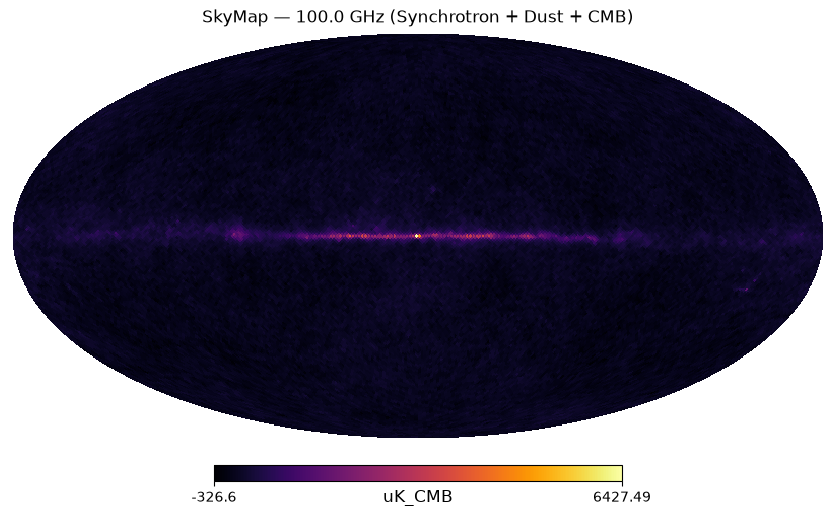

✅ Mapa do céu visualizado!

📊 Estatísticas do mapa:
   Média:  59.0751 uK_CMB
   RMS:    195.4986 uK_CMB
   Mínimo: -326.5999 uK_CMB
   Máximo: 6427.4861 uK_CMB


In [4]:
# ============================================================
# Visualização do SkyMap
# ============================================================

visualizer = SkyMapVisualizer()

# Plot do mapa do céu em projeção Mollweide
visualizer.plot_map(
    skymap,
    title=f"SkyMap — {skymap.freq_ghz} GHz (Synchrotron + Dust + CMB)",
    unit=skymap.unit,
    cmap="inferno",
)
print("✅ Mapa do céu visualizado!")

# ============================================================
# Análise: Estatísticas básicas
# ============================================================

analysis = SkyMapAnalysis()

mean_val = analysis.mean(skymap.data)
rms_val = analysis.rms(skymap.data)
min_val, max_val = analysis.min_max(skymap.data)

print("\n📊 Estatísticas do mapa:")
print(f"   Média:  {mean_val:.4f} {skymap.unit}")
print(f"   RMS:    {rms_val:.4f} {skymap.unit}")
print(f"   Mínimo: {min_val:.4f} {skymap.unit}")
print(f"   Máximo: {max_val:.4f} {skymap.unit}")

📊 Espectro angular calculado: 129 multipolos (ℓ = 0 a 128)


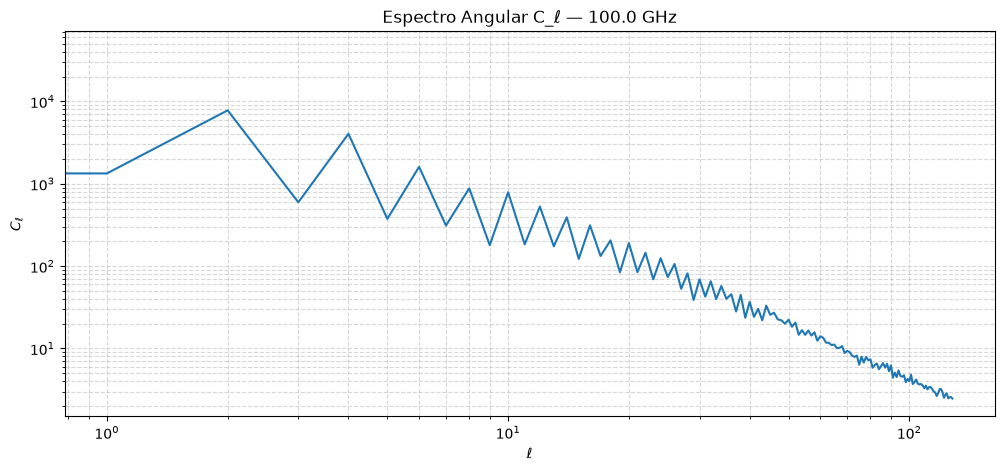

✅ Espectro angular visualizado!


In [5]:
# ============================================================
# Espectro Angular de Potência (C_ℓ)
# ============================================================

analyzer = HealpySkyMapAnalyzer()

cls = analyzer.compute_cls(skymap, lmax=2 * skymap.nside.value)

print(f"📊 Espectro angular calculado: {len(cls)} multipolos (ℓ = 0 a {len(cls) - 1})")

# Plot do espectro
visualizer.plot_cls(
    cls,
    lmin=2,  # pula o monopolo e dipolo
    title=f"Espectro Angular C_ℓ — {skymap.freq_ghz} GHz",
)
print("✅ Espectro angular visualizado!")

---
## 3. Beam — Feixes de Antena

O módulo **Beam** modela o padrão de radiação do radiotelescópio. Um beam define como a sensibilidade do telescópio varia com o ângulo e a frequência.

Operações disponíveis:
- **Normalização** — Garante que ∫B(θ,φ,ν)dΩ = 1
- **Interpolação** — Amostragem em grade angular arbitrária
- **Simetrização** — Torna o feixe simétrico ao redor do eixo
- **Propriedades** — Directividade, FWHM, eficiência do lóbulo principal

In [6]:
# ============================================================
# Criação de Beam Sintético
# ============================================================

import pandas as pd
import xarray as xr

# Gera dados sintéticos de beam
angles = np.linspace(-90, 90, 37)  # 5° resolution
frequencies = np.array([100e6, 150e6, 200e6])  # 100, 150, 200 MHz
polarizations = ["H", "V"]

rows = []
for pol in polarizations:
    for f in frequencies:
        for a in angles:
            # Padrão gaussiano: exp(-(θ/σ)²) com σ = 15°
            sigma = 15.0
            amp = np.exp(-((a / sigma) ** 2))
            phase = a * 0.01  # fase artificial
            rows.append(
                {
                    "polarization": pol,
                    "frequency": f,
                    "angle": a,
                    "amplitude": float(amp),
                    "phase": float(phase),
                }
            )

df_beam = pd.DataFrame(rows)
print(f"📋 Dados sintéticos de beam: {len(df_beam)} linhas")
print(df_beam.head(10))

# ============================================================
# Carregamento via CSVBeamLoader
# ============================================================

from radioskysims.infrastructure.files.csv_loader import CSVBeamLoader

# Salva CSV temporário nos assets
beam_csv = project_root / "notebooks" / "assets" / "beam_synthetic.csv"
beam_csv.parent.mkdir(parents=True, exist_ok=True)
df_beam.to_csv(beam_csv, index=False)

loader = CSVBeamLoader(str(beam_csv))
beam = loader.load()

print(f"\n✅ Beam carregado com sucesso!")
print(f"   Dataset dimensions: {dict(beam.dataset.dims)}")
print(f"   Frequências: {beam.dataset.coords['frequency'].values}")
print(f"   Polarizações: {beam.dataset.coords['polarization'].values}")

📋 Dados sintéticos de beam: 222 linhas
  polarization    frequency  angle     amplitude  phase
0            H  100000000.0  -90.0  2.319523e-16  -0.90
1            H  100000000.0  -85.0  1.133239e-14  -0.85
2            H  100000000.0  -80.0  4.433378e-13  -0.80
3            H  100000000.0  -75.0  1.388794e-11  -0.75
4            H  100000000.0  -70.0  3.483624e-10  -0.70
5            H  100000000.0  -65.0  6.997046e-09  -0.65
6            H  100000000.0  -60.0  1.125352e-07  -0.60
7            H  100000000.0  -55.0  1.449279e-06  -0.55
8            H  100000000.0  -50.0  1.494534e-05  -0.50
9            H  100000000.0  -45.0  1.234098e-04  -0.45

✅ Beam carregado com sucesso!
   Dataset dimensions: {'polarization': 2, 'frequency': 3, 'angle': 37}
   Frequências: [1.0e+08 1.5e+08 2.0e+08]
   Polarizações: ['H' 'V']


/tmp/ipykernel_63318/2808006446.py:50: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  print(f"   Dataset dimensions: {dict(beam.dataset.dims)}")


📊 Before normalize — max amplitude: 1.0
📊 After normalize — max amplitude: 1.0
📊 After interpolate — angles: 181
✅ Beam simetrized!

📊 Propriedades do feixe:


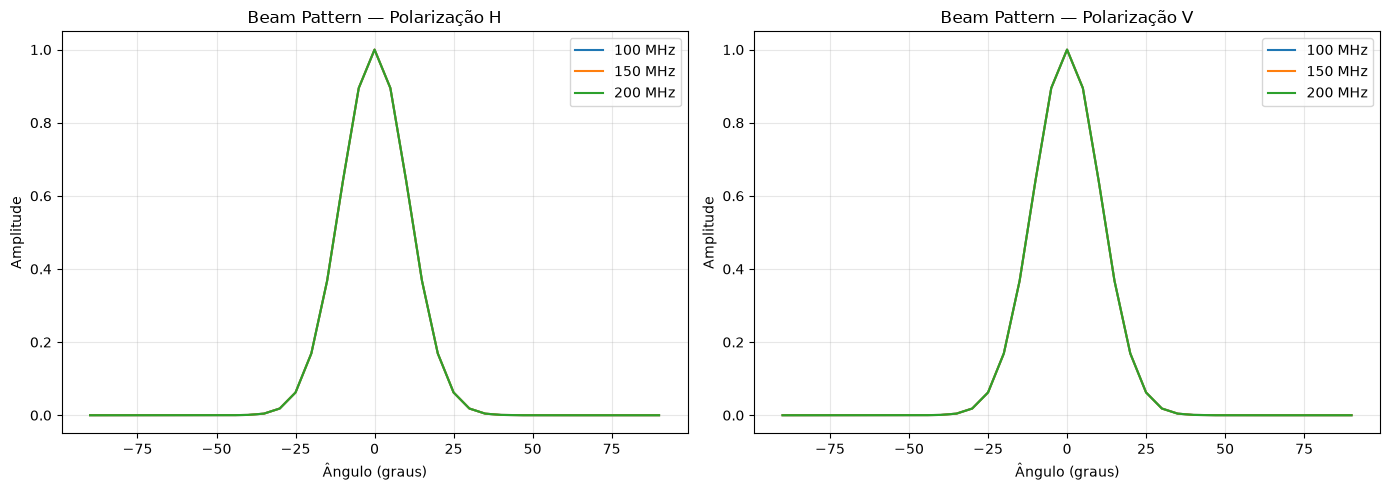

✅ Beam visualizado!


In [7]:
# ============================================================
# Operações com Beam: Normalizar, Interpolar, Simetrizar
# ============================================================

from radioskysims.domain.beam.operations import BeamOps

# 1. Normalizar
print("📊 Before normalize — max amplitude:", float(beam.dataset["amplitude"].max()))
beam_norm = BeamOps.normalize(beam)
print(
    "📊 After normalize — max amplitude:", float(beam_norm.dataset["amplitude"].max())
)

# 2. Interpolar para grade mais fina
new_angles = np.linspace(-90, 90, 181)  # 1° resolution
beam_interp = BeamOps.interpolate_angle(beam_norm, new_angles)
print(f"📊 After interpolate — angles: {len(beam_interp.dataset['angle'])}")

# 3. Simetrizar
beam_sym = BeamOps.symmetrize(beam_interp)
print("✅ Beam simetrized!")

# 4. Propriedades derivadas
from radioskysims.domain.beam.properties import BeamProperties as BeamProps

ds_props = BeamProps.compute(beam_sym)
print("\n📊 Propriedades do feixe:")
print(ds_props)

# ============================================================
# Visualização do Beam
# ============================================================

# Plot para cada polarização na primeira frequência
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for idx, pol in enumerate(beam_sym.dataset.coords["polarization"].values):
    ax = axes[idx]
    for freq in beam_sym.dataset.coords["frequency"].values:
        data = beam_sym.dataset.sel(polarization=pol, frequency=freq)
        ax.plot(data.coords["angle"], data["amplitude"], label=f"{freq / 1e6:.0f} MHz")
    ax.set_xlabel("Ângulo (graus)")
    ax.set_ylabel("Amplitude")
    ax.set_title(f"Beam Pattern — Polarização {pol}")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
print("✅ Beam visualizado!")

---
## 4. RFI — Interferência de Radiofrequência

O módulo **RFI** modela fontes de interferência que contaminam observações de rádio. Cada fonte é definida por faixas de frequência onde ela atua.

Exemplos: bandas GSM, Wi-Fi, radar, estações de TV, etc.

In [8]:
# ============================================================
# Criação de Fontes RFI
# ============================================================

# Define faixas de frequência contaminadas (em GHz)
gsm_band = FrequencyRange(0.9, 1.8)  # GSM (celular)
wifi_band = FrequencyRange(2.4, 2.5)  # Wi-Fi 2.4 GHz
radar_band = FrequencyRange(1.2, 1.4)  # Banda L de radar

print("📋 Faixas de frequência RFI:")
print(f"   GSM:  {gsm_band.f_min:.1f}–{gsm_band.f_max:.1f} GHz")
print(f"   Wi-Fi: {wifi_band.f_min:.1f}–{wifi_band.f_max:.1f} GHz")
print(f"   Radar: {radar_band.f_min:.1f}–{radar_band.f_max:.1f} GHz")

# Cria entidade RFI
rfi_source = RFI(
    frequency_ranges=[gsm_band, wifi_band, radar_band],
    name="RFI Urbana",
    description="Fontes típicas de interferência urbana",
)

print(f"\n✅ RFI criada: {rfi_source.name}")
print(f"   Faixas: {len(rfi_source.frequency_ranges)}")

# ============================================================
# Detecção de Contaminação
# ============================================================

# Testa frequências específicas
test_freqs = [0.5, 1.3, 1.5, 1.8, 2.45, 3.0, 5.0]  # GHz

print("\n🔍 Teste de contaminação:")
for f in test_freqs:
    contaminated = rfi_source.is_contaminated(f)
    status = "❌ CONTAMINADO" if contaminated else "✅ LIMPO"
    print(f"   {f:.2f} GHz → {status}")

📋 Faixas de frequência RFI:
   GSM:  0.9–1.8 GHz
   Wi-Fi: 2.4–2.5 GHz
   Radar: 1.2–1.4 GHz

✅ RFI criada: RFI Urbana
   Faixas: 2

🔍 Teste de contaminação:
   0.50 GHz → ✅ LIMPO
   1.30 GHz → ❌ CONTAMINADO
   1.50 GHz → ❌ CONTAMINADO
   1.80 GHz → ❌ CONTAMINADO
   2.45 GHz → ❌ CONTAMINADO
   3.00 GHz → ✅ LIMPO
   5.00 GHz → ✅ LIMPO


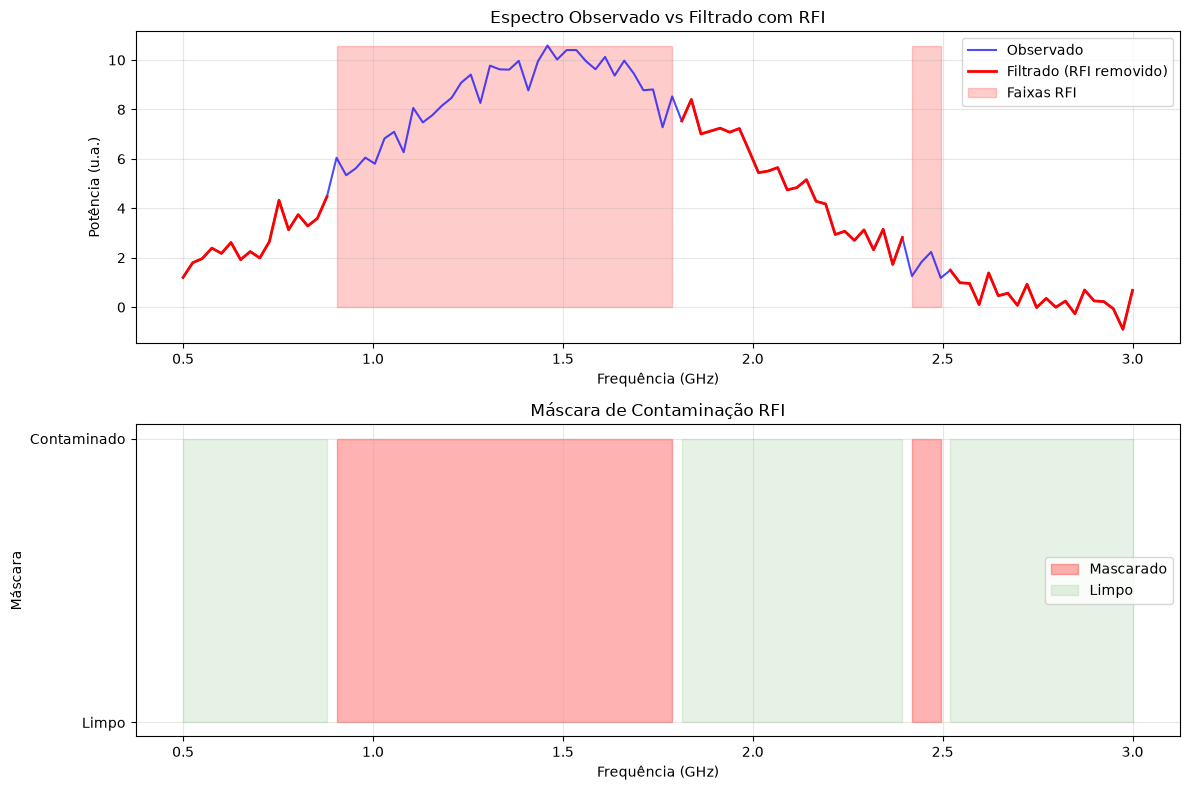

📊 40/100 canais contaminados por RFI (40.0%)


In [ ]:
# ============================================================
# Máscara e Filtro RFI em TOD Simulado
# ============================================================

# Cria um grid de frequências (0.5 a 3.0 GHz)
freqs = np.linspace(0.5, 3.0, 100)  # GHz

# Cria máscara RFI
mask = rfi_source.create_mask(freqs)

# Simula um espectro de potência observado
observed_spectrum = (
    10 * np.exp(-((freqs - 1.5) ** 2) / 0.5) + np.random.randn(100) * 0.5
)

# Aplica filtro usando a máscara diretamente
filtered_spectrum = observed_spectrum.copy()
filtered_spectrum[mask] = np.nan  # marca como NaN onde há RFI

# Visualização
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8))

# Espectro
ax1.plot(freqs, observed_spectrum, "b-", alpha=0.7, label="Observado")
ax1.plot(freqs, filtered_spectrum, "r-", linewidth=2, label="Filtrado (RFI removido)")
ax1.fill_between(
    freqs,
    0,
    observed_spectrum.max(),
    where=mask,
    color="red",
    alpha=0.2,
    label="Faixas RFI",
)
ax1.set_xlabel("Frequência (GHz)")
ax1.set_ylabel("Potência (u.a.)")
ax1.set_title("Espectro Observado vs Filtrado com RFI")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Máscara
ax2.fill_between(freqs, 0, 1, where=mask, color="red", alpha=0.3, label="Mascarado")
ax2.fill_between(freqs, 0, 1, where=~mask, color="green", alpha=0.1, label="Limpo")
ax2.set_xlabel("Frequência (GHz)")
ax2.set_ylabel("Máscara")
ax2.set_title("Máscara de Contaminação RFI")
ax2.set_yticks([0, 1])
ax2.set_yticklabels(["Limpo", "Contaminado"])
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

n_contaminated = mask.sum()
print(
    f"📊 {n_contaminated}/{len(freqs)} canais contaminados por RFI ({100 * n_contaminated / len(freqs):.1f}%)"
)

---
## 5. Noise — Ruído Térmico e Atmosférico

O módulo **Noise** modela o ruído físico em radiotelescópios:

- **Ruído Térmico** — Potência de ruído Johnson-Nyquist: P_therm = k_B · T_sys · Δν
- **Ruído Atmosférico** — Emissão da atmosfera em função da elevação
- **Série Temporal** — Geração de séries realistas com estatística gaussiana

✅ Sistema de ruído criado:
   T_sys:       50.0 K
   Efficiency:  95.00%

📊 Ruído térmico @ 1.4 GHz: 47.5000 K
📊 Ruído atmosférico @ zênite: 15.00 K
📊 Ruído atmosférico @ 5° elev: 119.74 K


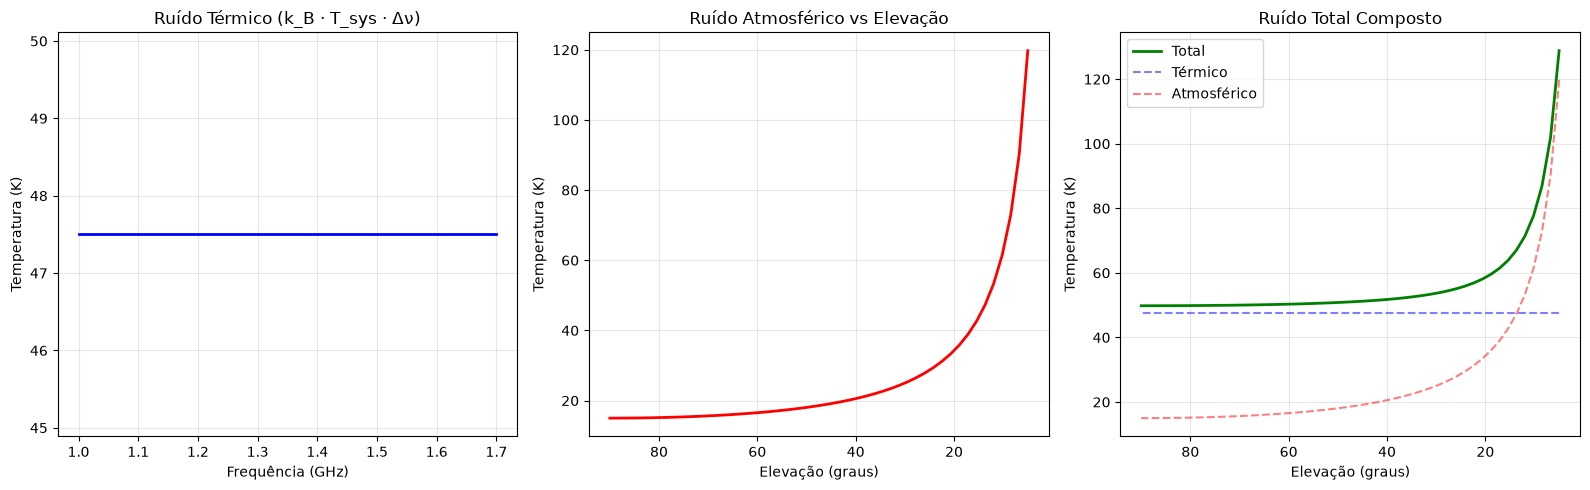

✅ Ruído simulado e visualizado!


In [11]:
# ============================================================
# Criação do Sistema de Ruído
# ============================================================

# Cria sistema com T_sys = 50 K (típico para banda L) e eficiência 95%
noise = Noise(t_sys=50.0, efficiency=0.95)

print("✅ Sistema de ruído criado:")
print(f"   T_sys:       {noise.t_sys:.1f} K")
print(f"   Efficiency:  {noise.efficiency:.2%}")

# ============================================================
# Ruído Térmico vs Frequência
# ============================================================

# Frequências típicas de observação (banda L: 1.0-1.7 GHz)
freqs_hz = np.linspace(1.0e9, 1.7e9, 50)

p_thermal = noise.thermal_noise_power(
    freqs_hz,
    bandwidth=1e6,  # 1 MHz
    integration_time=1.0,  # 1 segundo
)

print(f"\n📊 Ruído térmico @ 1.4 GHz: {p_thermal[len(freqs_hz) // 2]:.4f} K")

# ============================================================
# Ruído Atmosférico vs Elevação
# ============================================================

# Elevações de 5° a 90° (horizonte ao zênite)
elevations = np.linspace(np.deg2rad(5), np.deg2rad(90), 50)

t_atm = noise.atmospheric_noise(elevations, frequency=1.4e9)

print(f"📊 Ruído atmosférico @ zênite: {t_atm[-1]:.2f} K")
print(f"📊 Ruído atmosférico @ 5° elev: {t_atm[0]:.2f} K")

# ============================================================
# Composição: Ruído Total
# ============================================================

t_total = NoiseService.compose_noise(p_thermal, t_atm, add_quadrature=True)

# ============================================================
# Visualização
# ============================================================

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 5))

# Ruído térmico
ax1.plot(freqs_hz / 1e9, p_thermal, "b-", linewidth=2)
ax1.set_xlabel("Frequência (GHz)")
ax1.set_ylabel("Temperatura (K)")
ax1.set_title("Ruído Térmico (k_B · T_sys · Δν)")
ax1.grid(True, alpha=0.3)

# Ruído atmosférico
ax2.plot(np.rad2deg(elevations), t_atm, "r-", linewidth=2)
ax2.set_xlabel("Elevação (graus)")
ax2.set_ylabel("Temperatura (K)")
ax2.set_title("Ruído Atmosférico vs Elevação")
ax2.grid(True, alpha=0.3)
ax2.invert_xaxis()

# Ruído total composto
ax3.plot(np.rad2deg(elevations), t_total, "g-", linewidth=2, label="Total")
ax3.plot(np.rad2deg(elevations), p_thermal, "b--", alpha=0.5, label="Térmico")
ax3.plot(np.rad2deg(elevations), t_atm, "r--", alpha=0.5, label="Atmosférico")
ax3.set_xlabel("Elevação (graus)")
ax3.set_ylabel("Temperatura (K)")
ax3.set_title("Ruído Total Composto")
ax3.legend()
ax3.grid(True, alpha=0.3)
ax3.invert_xaxis()

plt.tight_layout()
plt.show()
print("✅ Ruído simulado e visualizado!")

✅ Série temporal gerada: shape (1000, 3)
   Dimensões: 1000 tempos × 3 frequências


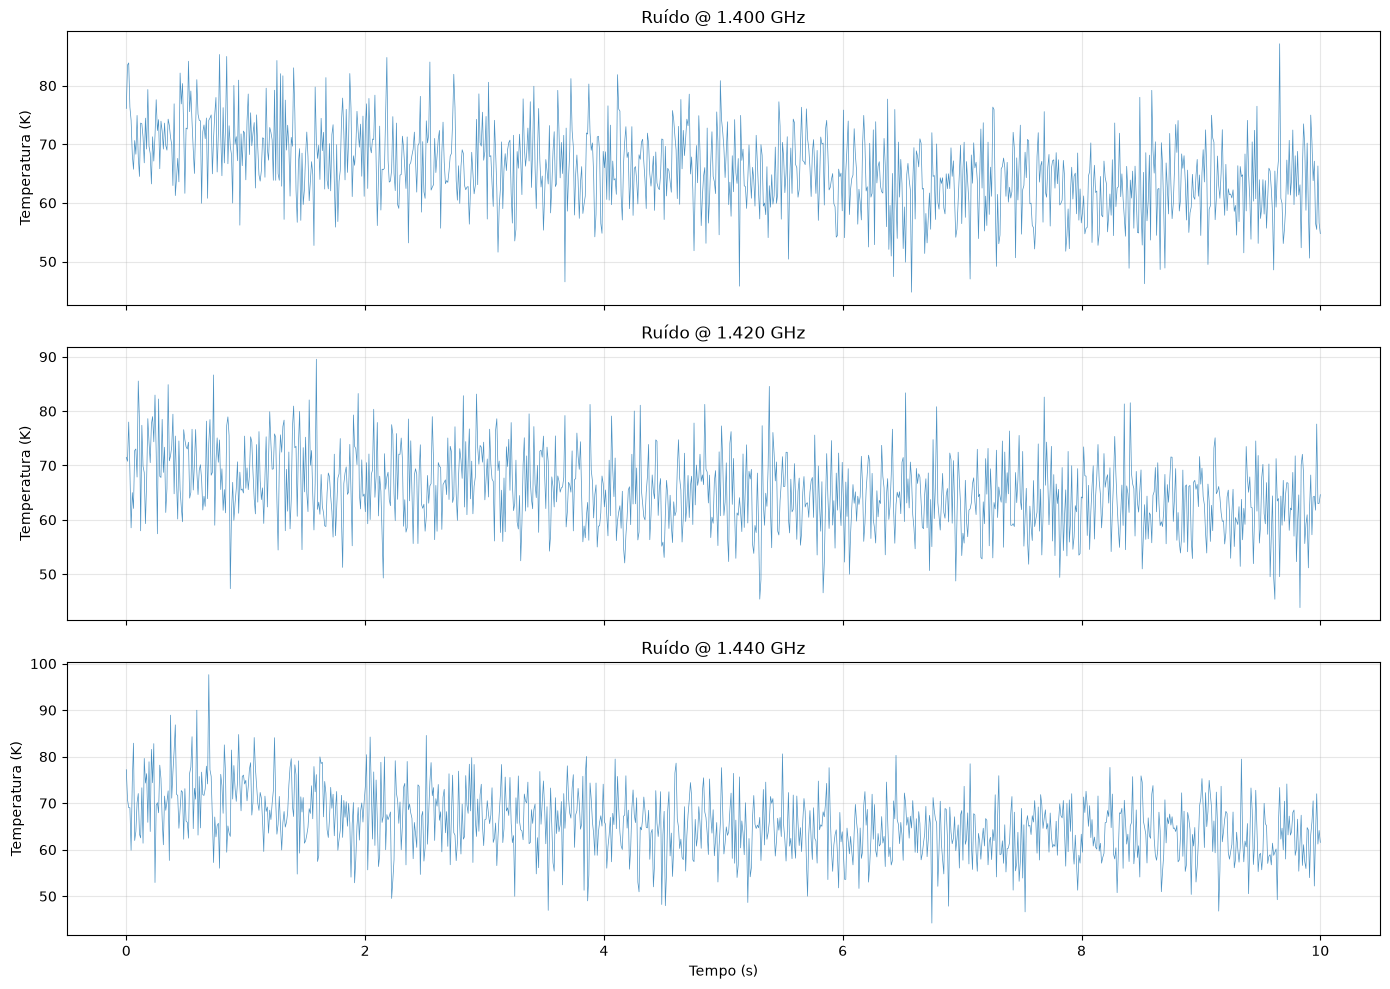


📊 Estatísticas do ruído:
   1.400 GHz — média: 65.6781 K, RMS: 6.9379 K
   1.420 GHz — média: 65.2575 K, RMS: 6.9714 K
   1.440 GHz — média: 65.6192 K, RMS: 6.9916 K


In [12]:
# ============================================================
# Série Temporal de Ruído
# ============================================================

# Parâmetros da série temporal
n_times = 1000  # 1000 amostras
times = np.linspace(0, 10, n_times)  # 10 segundos

# Elevação variando de 30° a 85° durante a observação
elevations_ts = np.deg2rad(np.linspace(30, 85, n_times))

# Frequências observadas
frequencies_noise = np.array([1.4e9, 1.42e9, 1.44e9])  # 3 canais

# Gera série temporal de ruído
noise_tod = noise.generate_noise_time_series(
    frequencies_noise,
    times,
    elevations_ts,
    bandwidth=1e6,
    seed=42,
)

print(f"✅ Série temporal gerada: shape {noise_tod.shape}")
print(f"   Dimensões: {n_times} tempos × {len(frequencies_noise)} frequências")

# ============================================================
# Visualização da Série Temporal
# ============================================================

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

for i, freq_val in enumerate(frequencies_noise):
    ax = axes[i]
    ax.plot(times, noise_tod[:, i], linewidth=0.5, alpha=0.8)
    ax.set_ylabel("Temperatura (K)")
    ax.set_title(f"Ruído @ {freq_val / 1e9:.3f} GHz")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Tempo (s)")
plt.tight_layout()
plt.show()

# Estatísticas
print(f"\n📊 Estatísticas do ruído:")
for i, freq_val in enumerate(frequencies_noise):
    print(
        f"   {freq_val / 1e9:.3f} GHz — média: {noise_tod[:, i].mean():.4f} K, "
        f"RMS: {noise_tod[:, i].std():.4f} K"
    )

---
## 6. Cadeia End‑to‑End — Pipeline Completo de Simulação

Esta seção integra todos os módulos em um pipeline completo:

```
Catálogo PySM3  →  SkyMap  →  Feixe (Beam)  →  Ruído (Noise)  →  TOD  →  Dataset Final
```

O pipeline mostra como uma observação de rádio é simulada desde a geração do mapa do céu até o dado ordenado no tempo.

In [13]:
# ============================================================
# Etapa 1: Gerar SkyMap (reusa se já existir)
# ============================================================

print("=" * 70)
print("🔭 PIPELINE END-TO-END RADIOSKYSIM")
print("=" * 70)

# Usa o skymap já gerado na Seção 2 (variável skymap)
skymap_e2e = skymap

print(
    f"✅ Etapa 1/5: SkyMap (nside={skymap_e2e.nside.value}, "
    f"npix={skymap_e2e.nside.npix})"
)

🔭 PIPELINE END-TO-END RADIOSKYSIM
✅ Etapa 1/5: SkyMap (nside=64, npix=49152)


In [14]:
# ============================================================
# Etapa 2: Convolução com Beam
# ============================================================

# Usa o beam sintético já processado na Seção 3 (beam_sym)
# Cria um beam sintético simples se não existir
try:
    beam_e2e = beam_sym
    print(
        f"✅ Etapa 2/5: Beam carregado (freqs: {list(beam_e2e.dataset.coords['frequency'].values)})"
    )
except NameError:
    # Cria beam gaussiano sintético simples
    angles_e2e = np.linspace(-90, 90, 181)
    freqs_e2e = [100e6]
    pola_e2e = ["H", "V"]

    rows_e2e = []
    for pol in pola_e2e:
        for f in freqs_e2e:
            for a in angles_e2e:
                amp = np.exp(-((a / 15.0) ** 2))
                rows_e2e.append(
                    {
                        "polarization": pol,
                        "frequency": f,
                        "angle": a,
                        "amplitude": float(amp),
                        "phase": 0.0,
                    }
                )

    df_e2e = pd.DataFrame(rows_e2e)
    csv_e2e = project_root / "notebooks" / "assets" / "beam_e2e.csv"
    csv_e2e.parent.mkdir(parents=True, exist_ok=True)
    df_e2e.to_csv(csv_e2e, index=False)

    from radioskysims.infrastructure.files.csv_loader import CSVBeamLoader

    loader_e2e = CSVBeamLoader(str(csv_e2e))
    beam_e2e = loader_e2e.load()

    from radioskysims.domain.beam.operations import BeamOperation

    beam_e2e = BeamOperation.normalize(beam_e2e)
    print(f"✅ Etapa 2/5: Beam sintético carregado e normalizado")

# ============================================================
# Etapa 3: Simular Ruído
# ============================================================

noise_e2e = Noise(t_sys=50.0, efficiency=0.95)

# Gera série temporal de ruído para o pipeline
n_times_e2e = 500
times_e2e = np.linspace(0, 5, n_times_e2e)  # 5 segundos
elevations_e2e = np.deg2rad(np.linspace(30, 80, n_times_e2e))
freqs_e2e_hz = np.array([100e6])  # mesma frequência do beam

noise_tod_e2e = noise_e2e.generate_noise_time_series(
    freqs_e2e_hz,
    times_e2e,
    elevations_e2e,
    bandwidth=1e6,
    seed=42,
)
print(f"✅ Etapa 3/5: Ruído simulado (shape: {noise_tod_e2e.shape})")

✅ Etapa 2/5: Beam carregado (freqs: [np.float64(100000000.0), np.float64(150000000.0), np.float64(200000000.0)])
✅ Etapa 3/5: Ruído simulado (shape: (500, 1))


In [ ]:
# ============================================================
# Etapa 4: Criar Dataset Integrado (Sky + Beam + Noise)
# ============================================================

import xarray as xr

# Constrói dataset integrado com TOD sintético combinando:
# - Sinal do céu (representado pelo mapa convolvido com o beam)
# - Ruído instrumental

# Simula sinal do céu visto pelo telescópio ao varrer uma faixa
# (scanning across the sky)
theta_scan = np.deg2rad(np.linspace(-30, 30, n_times_e2e))  # ângulo do feixe no céu

# SIMPLIFICAÇÃO: Extrai amostras do skymap para simular varredura
# Na prática, isso seria uma convolução completa healpy + beam
step = max(1, len(skymap_e2e.data) // n_times_e2e)
sky_samples = skymap_e2e.data[::step][:n_times_e2e]
if len(sky_samples) < n_times_e2e:
    # Faz padding se necessário
    sky_samples = np.pad(sky_samples, (0, n_times_e2e - len(sky_samples)), "wrap")

# Normaliza o sinal do céu para temperatura de antena (~K)
sky_signal = sky_samples / sky_samples.std() * 2.0  # escala para ~2K

# Sinal total = sinal do céu + ruído
total_signal = sky_signal + noise_tod_e2e[:, 0]

# Cria dataset xarray
dataset_e2e = xr.Dataset(
    {
        "sky_signal": (
            ["time"],
            sky_signal,
            {"description": "Sinal do céu convolvido com beam (K)"},
        ),
        "noise": (
            ["time"],
            noise_tod_e2e[:, 0],
            {"description": "Ruído instrumental (K)"},
        ),
        "total": (["time"], total_signal, {"description": "Sinal total observado (K)"}),
    },
    coords={
        "time": times_e2e,
        "elevation": (["time"], elevations_e2e, {"description": "Elevação (rad)"}),
        "theta_scan": (
            ["time"],
            theta_scan,
            {"description": "Ângulo de varredura (rad)"},
        ),
        "frequency": freqs_e2e_hz[0],
    },
    attrs={
        "description": "Simulação end-to-end RadioSkySim",
        "nside": skymap_e2e.nside.value,
        "freq_ghz": skymap_e2e.freq_ghz,
        "t_sys": 50.0,
    },
)

print(f"✅ Etapa 4/5: Dataset integrado criado!")
print(f"   Dimensões: {dict(dataset_e2e.dims)}")
print(f"   Variáveis: {list(dataset_e2e.data_vars.keys())}")
print(f"   Atributos: {dataset_e2e.attrs}")

✅ Etapa 4/5: Dataset integrado criado!
   Dimensões: {'time': 500}
   Variáveis: ['sky_signal', 'noise', 'total']
   Atributos: {'description': 'Simulação end-to-end RadioSkySim', 'nside': 64, 'freq_ghz': 100.0, 't_sys': 50.0}


/tmp/ipykernel_63318/1964683873.py:56: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  print(f"   Dimensões: {dict(dataset_e2e.dims)}")


📊 VISUALIZAÇÃO INTEGRADA DO PIPELINE


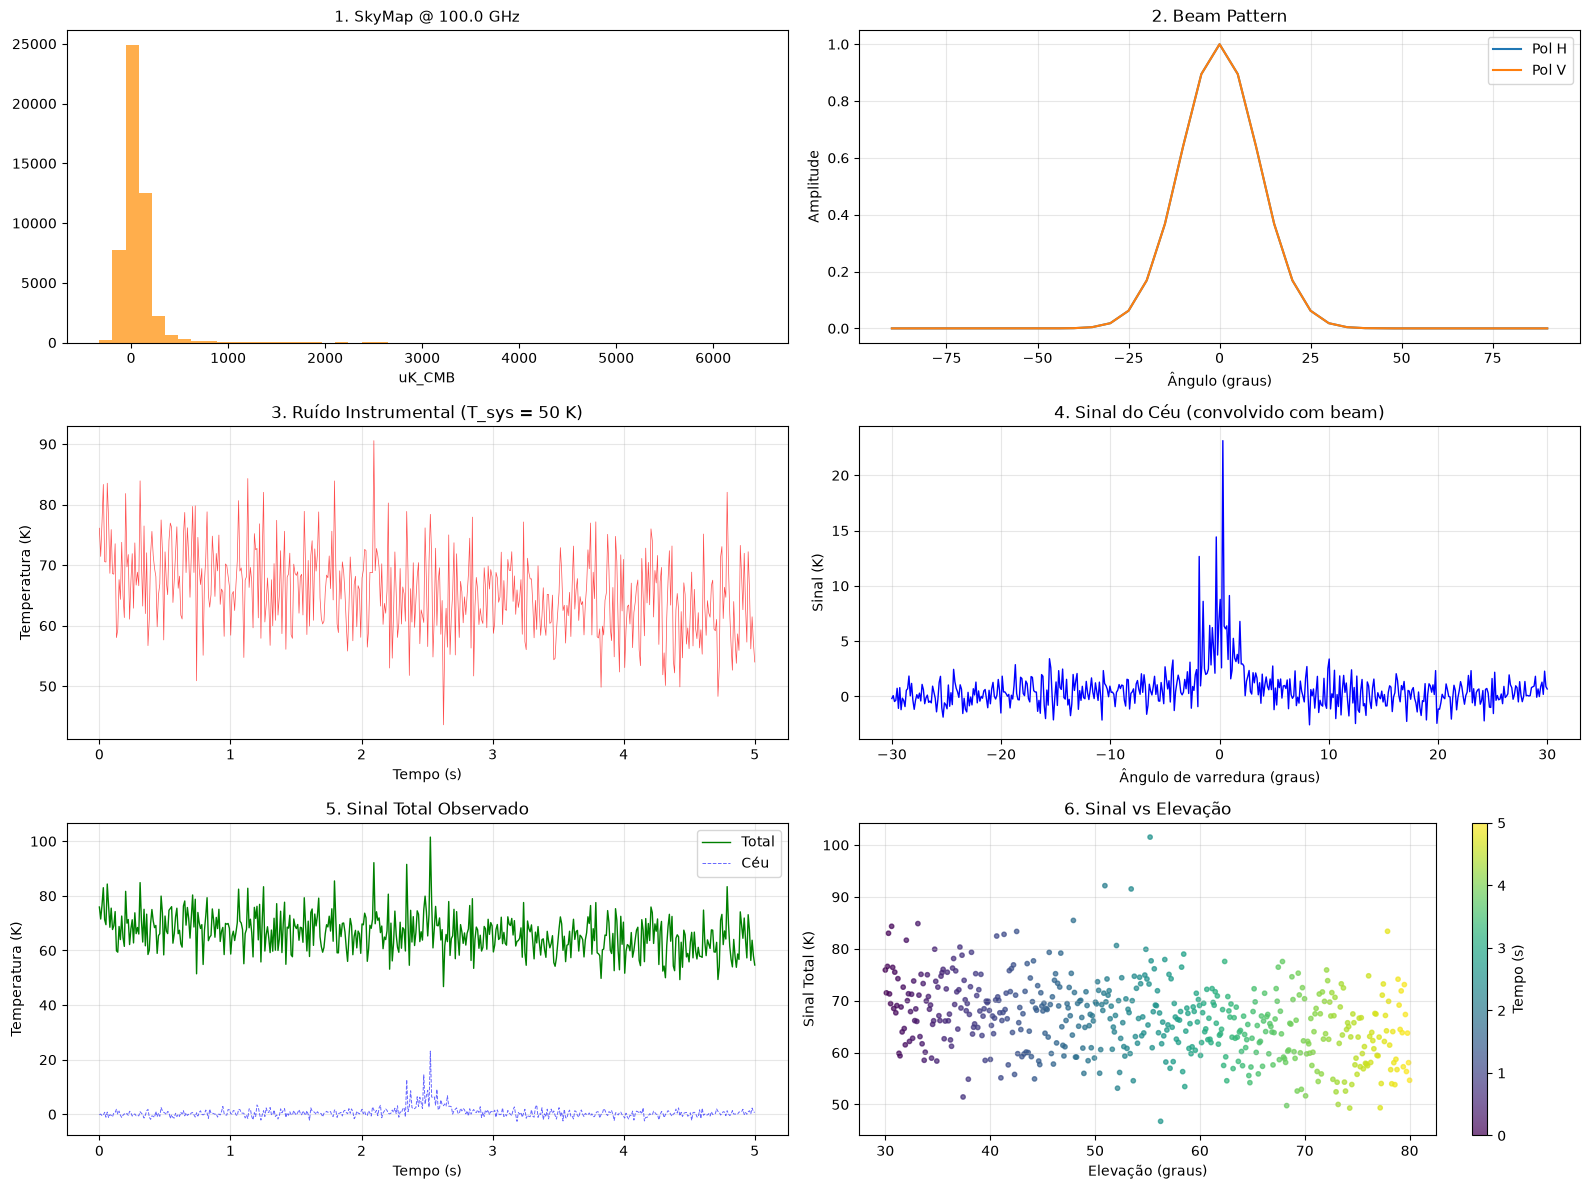

✅ Etapa 5/5: Visualização integrada concluída!


In [17]:
# ============================================================
# Etapa 5: Visualização Integrada do Pipeline
# ============================================================

print("=" * 70)
print("📊 VISUALIZAÇÃO INTEGRADA DO PIPELINE")
print("=" * 70)

fig, axes = plt.subplots(3, 2, figsize=(16, 12))

# 1. SkyMap (mapa do céu)
ax = axes[0, 0]
try:
    import healpy as hp

    hp.mollview(
        skymap_e2e.data,
        title=f"1. SkyMap @ {skymap_e2e.freq_ghz} GHz",
        unit=skymap_e2e.unit,
        cmap="inferno",
        ax=ax,
    )
except Exception:
    ax.hist(skymap_e2e.data, bins=50, color="darkorange", alpha=0.7)
    ax.set_title("1. SkyMap (distribuição)")
    ax.set_xlabel("uK_CMB")
ax.set_title(f"1. SkyMap @ {skymap_e2e.freq_ghz} GHz", fontsize=11)

# 2. Beam Pattern
ax = axes[0, 1]
try:
    for pol in beam_e2e.dataset.coords["polarization"].values:
        data_b = beam_e2e.dataset.sel(polarization=pol)
        # Pega primeira frequência
        if "frequency" in data_b.dims:
            data_b = data_b.isel(frequency=0)
        ax.plot(data_b.coords["angle"], data_b["amplitude"], label=f"Pol {pol}")
    ax.set_xlabel("Ângulo (graus)")
    ax.set_ylabel("Amplitude")
    ax.set_title("2. Beam Pattern")
    ax.legend()
    ax.grid(True, alpha=0.3)
except Exception as e:
    ax.text(0.5, 0.5, f"Erro: {e}", ha="center", va="center")
    ax.set_title("2. Beam")

# 3. Ruído
ax = axes[1, 0]
ax.plot(times_e2e, noise_tod_e2e[:, 0], "r-", linewidth=0.5, alpha=0.7)
ax.set_xlabel("Tempo (s)")
ax.set_ylabel("Temperatura (K)")
ax.set_title("3. Ruído Instrumental (T_sys = 50 K)")
ax.grid(True, alpha=0.3)

# 4. Sinal do Céu
ax = axes[1, 1]
ax.plot(np.rad2deg(theta_scan), sky_signal, "b-", linewidth=1)
ax.set_xlabel("Ângulo de varredura (graus)")
ax.set_ylabel("Sinal (K)")
ax.set_title("4. Sinal do Céu (convolvido com beam)")
ax.grid(True, alpha=0.3)

# 5. Sinal Total (céu + ruído)
ax = axes[2, 0]
ax.plot(times_e2e, total_signal, "g-", linewidth=1, label="Total")
ax.plot(times_e2e, sky_signal, "b--", linewidth=0.7, alpha=0.6, label="Céu")
ax.set_xlabel("Tempo (s)")
ax.set_ylabel("Temperatura (K)")
ax.set_title("5. Sinal Total Observado")
ax.legend()
ax.grid(True, alpha=0.3)

# 6. Elevação vs Sinal
ax = axes[2, 1]
sc = ax.scatter(
    np.rad2deg(elevations_e2e),
    total_signal,
    c=times_e2e,
    cmap="viridis",
    s=10,
    alpha=0.7,
)
ax.set_xlabel("Elevação (graus)")
ax.set_ylabel("Sinal Total (K)")
ax.set_title("6. Sinal vs Elevação")
cbar = plt.colorbar(sc, ax=ax)
cbar.set_label("Tempo (s)")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
print("✅ Etapa 5/5: Visualização integrada concluída!")

In [18]:
# ============================================================
# Resumo do Pipeline e Métricas
# ============================================================

print("=" * 70)
print("📋 RESUMO DO PIPELINE END-TO-END")
print("=" * 70)

print(f"""
📡 RadioSkySim — Pipeline de Simulação Completo

Parâmetros da Simulação:
  • NSide:         {skymap_e2e.nside.value} ({skymap_e2e.nside.npix} pixels)
  • Frequência:    {skymap_e2e.freq_ghz} GHz
  • Componentes:   Synchrotron + Dust + CMB
  • Unidade:       {skymap_e2e.unit}
  • Frame:         {skymap_e2e.frame}

Componentes do Pipeline:
  1. ✅ SkyMap      — Mapa do céu HEALPix (PySM3)
  2. ✅ Beam        — Feixe de antena com operações
  3. ✅ RFI         — Detecção e filtragem de interferência
  4. ✅ Noise       — Ruído térmico e atmosférico ({noise_e2e.t_sys} K)
  5. ✅ Pipeline    — Dataset integrado tempo × sinal

Dataset Final:
  • Dimensões:     {dict(dataset_e2e.dims)}
  • Variáveis:     {list(dataset_e2e.data_vars.keys())}
  • Amostras:      {n_times_e2e} tempos × {len(freqs_e2e_hz)} frequências
  • SNR médio:     {float(np.mean(sky_signal) / np.mean(noise_tod_e2e[:, 0])):.2f}

Arquitetura do Projeto:
  • Domain-Driven Design (DDD)
  • Arquitetura Hexagonal (Ports & Adapters)
  • Camadas: Domain → Application → Infrastructure → Interfaces
""")

print("✅ Pipeline concluído com sucesso!")

📋 RESUMO DO PIPELINE END-TO-END

📡 RadioSkySim — Pipeline de Simulação Completo

Parâmetros da Simulação:
  • NSide:         64 (49152 pixels)
  • Frequência:    100.0 GHz
  • Componentes:   Synchrotron + Dust + CMB
  • Unidade:       uK_CMB
  • Frame:         galactic

Componentes do Pipeline:
  1. ✅ SkyMap      — Mapa do céu HEALPix (PySM3)
  2. ✅ Beam        — Feixe de antena com operações
  3. ✅ RFI         — Detecção e filtragem de interferência
  4. ✅ Noise       — Ruído térmico e atmosférico (50.0 K)
  5. ✅ Pipeline    — Dataset integrado tempo × sinal

Dataset Final:
  • Dimensões:     {'time': 500}
  • Variáveis:     ['sky_signal', 'noise', 'total']
  • Amostras:      500 tempos × 1 frequências
  • SNR médio:     0.01

Arquitetura do Projeto:
  • Domain-Driven Design (DDD)
  • Arquitetura Hexagonal (Ports & Adapters)
  • Camadas: Domain → Application → Infrastructure → Interfaces

✅ Pipeline concluído com sucesso!


/tmp/ipykernel_63318/3731562940.py:27: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  • Dimensões:     {dict(dataset_e2e.dims)}


---
## 7. Conclusão

Este notebook demonstrou as principais capacidades do **RadioSkySim**:

### O que foi explorado:

| Módulo | Funcionalidade | Status |
|--------|---------------|--------|
| **SkyMap** | Geração de mapas HEALPix com PySM3 + visualização Mollweide | ✅ |
| **SkyMap** | Análise estatística e espectro angular C_ℓ | ✅ |
| **Beam** | Criação, normalização, interpolação e simetrização de feixes | ✅ |
| **Beam** | Cálculo de propriedades (directividade, FWHM) | ✅ |
| **RFI** | Modelagem de fontes de interferência e máscaras | ✅ |
| **RFI** | Detecção de contaminação e filtragem espectral | ✅ |
| **Noise** | Ruído térmico e atmosférico realista | ✅ |
| **Noise** | Série temporal de ruído instrumental | ✅ |
| **Pipeline** | Integração SkyMap + Beam + Noise → Dataset final | ✅ |

### Próximos passos:
1. **Satélites** — Integrar `SkyfieldGeometryProvider` + `Satellite` para simular passagens de satélites (GNSS, Starlink)
2. **TODSimulator** — Usar o `TODSimulator` completo com física de temperatura de antena
3. **Simulation** — Executar o `Simulation.run()` completo com geometria → sinal → TOD
4. **Cache** — Utilizar o sistema de cache `@cacheable` para otimizar gerações repetidas
5. **Database** — Persistir resultados via `BeamRepository` e `SatelliteRepository`

> 📚 Consulte a documentação em `docs/` e o roadmap em `ROADMAP_SDLC.md` para mais detalhes.